# Week 6: Feature Engineering
## Project: Moneyball – IPL Player Valuation

### Objective
To prepare IPL auction and performance data for analysis by applying feature engineering techniques.

### Tasks
1. Normalization and scaling of numerical features.
2. Encoding categorical variables.
3. Identifying and correcting skewness in numerical data.

### Tools Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

### Expected Outcome
A transformed dataset suitable for further statistical analysis and dimensionality reduction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.preprocessing import LabelEncoder, PowerTransformer

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os
import pandas as pd

data_folder = r"D:\DSD\College\DSV\Project\archive\moneyball\datasets"

auction = pd.read_excel(os.path.join(data_folder, "Auction.xlsx"))
batsmen = pd.read_excel(os.path.join(data_folder, "Top_100_batsman.xlsx"))
bowlers = pd.read_excel(os.path.join(data_folder, "Top_100_bowlers.xlsx"))
matches = pd.read_csv(os.path.join(data_folder, "matches.csv"))

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [3]:
datasets = {
    "Auction": auction,
    "Batsmen": batsmen,
    "Bowlers": bowlers,
    "Matches": matches
}

for name, df in datasets.items():
    print(f"\n--- {name} Dataset ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nData Types:")
    print(df.dtypes)


--- Auction Dataset ---
Shape: (56, 5)
Columns: ['TEAM', 'PLAYER', 'TYPE', 'PRICE(In crore Indian Rupees) ', 'YEAR']

Data Types:
TEAM                                  str
PLAYER                                str
TYPE                                  str
PRICE(In crore Indian Rupees)     float64
YEAR                                int64
dtype: object

--- Batsmen Dataset ---
Shape: (100, 14)
Columns: ['POS', 'PLAYER', 'Mat', 'Inns', 'NO', 'Runs', 'HS', 'Avg', 'BF', 'SR', 100, 50, '4s', '6s']

Data Types:
POS         int64
PLAYER        str
Mat         int64
Inns        int64
NO          int64
Runs        int64
HS         object
Avg       float64
BF          int64
SR        float64
100         int64
50          int64
4s          int64
6s          int64
dtype: object

--- Bowlers Dataset ---
Shape: (100, 13)
Columns: ['POS', 'PLAYER', 'Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'BBI', 'Avg', 'Econ', 'SR', '4w', '5w']

Data Types:
POS         int64
PLAYER        str
Mat         int64
Inns     

In [4]:
# Identify numerical and categorical columns
numerical_cols = auction.select_dtypes(include=np.number).columns.tolist()
categorical_cols = auction.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nTotal Numerical Columns:", len(numerical_cols))
print("Total Categorical Columns:", len(categorical_cols))

Numerical Columns:
['PRICE(In crore Indian Rupees) ', 'YEAR']

Categorical Columns:
['TEAM', 'PLAYER', 'TYPE']

Total Numerical Columns: 2
Total Categorical Columns: 3


C:\Users\Divyesh D S\AppData\Local\Temp\ipykernel_2592\2996947723.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = auction.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [6]:
# Select the auction price column
price_col = "PRICE(In crore Indian Rupees) "

auction_features = auction[[price_col]].copy()

print("Selected Numerical Feature:")
print(auction_features.head())

print("\nSummary Statistics:")
print(auction_features.describe())

Selected Numerical Feature:
   PRICE(In crore Indian Rupees) 
0                           15.50
1                           10.75
2                           10.00
3                            8.50
4                            8.00

Summary Statistics:
       PRICE(In crore Indian Rupees) 
count                       56.000000
mean                         7.636607
std                          3.295155
min                          3.000000
25%                          5.000000
50%                          7.000000
75%                          9.525000
max                         16.000000


In [7]:
# Apply Min-Max Normalization
minmax_scaler = MinMaxScaler()

auction_features["Normalized_Price"] = minmax_scaler.fit_transform(
    auction_features[[price_col]]
)

print(auction_features.head(10))

   PRICE(In crore Indian Rupees)   Normalized_Price
0                           15.50          0.961538
1                           10.75          0.596154
2                           10.00          0.538462
3                            8.50          0.423077
4                            8.00          0.384615
5                            7.75          0.365385
6                            6.75          0.288462
7                            5.50          0.192308
8                            8.40          0.415385
9                            8.40          0.415385


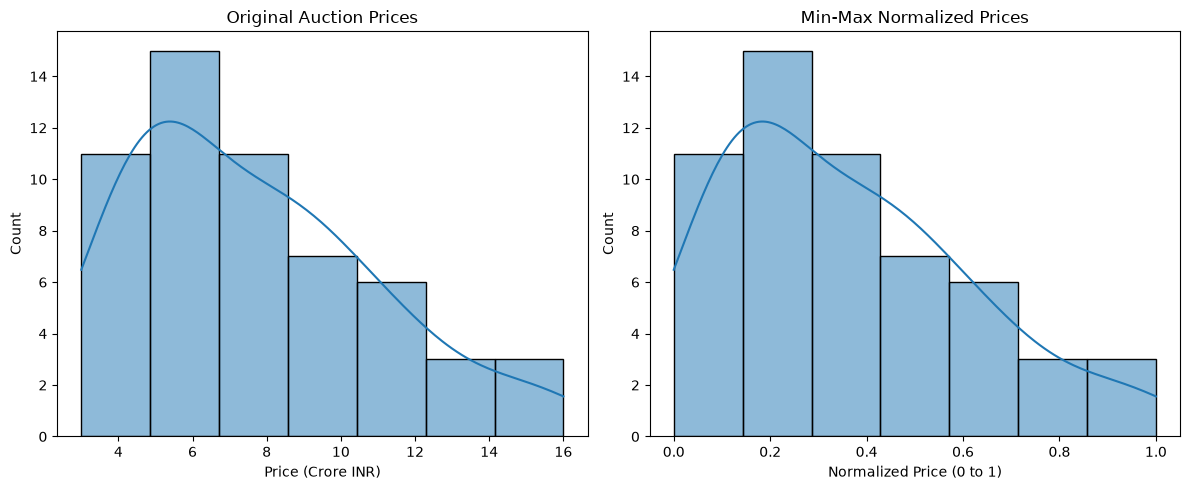

In [8]:
# Compare original and normalized price distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(auction_features[price_col].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Original Auction Prices")
axes[0].set_xlabel("Price (Crore INR)")

sns.histplot(auction_features["Normalized_Price"].dropna(), kde=True, ax=axes[1])
axes[1].set_title("Min-Max Normalized Prices")
axes[1].set_xlabel("Normalized Price (0 to 1)")

plt.tight_layout()
plt.show()

In [9]:
# Apply Standard Scaling
standard_scaler = StandardScaler()

auction_features["Standardized_Price"] = standard_scaler.fit_transform(
    auction_features[[price_col]]
)

print(auction_features[[price_col, "Normalized_Price", "Standardized_Price"]].head(10))

print("\nMean after scaling:", auction_features["Standardized_Price"].mean())
print("Standard deviation after scaling:", auction_features["Standardized_Price"].std(ddof=0))

   PRICE(In crore Indian Rupees)   Normalized_Price  Standardized_Price
0                           15.50          0.961538            2.407946
1                           10.75          0.596154            0.953390
2                           10.00          0.538462            0.723724
3                            8.50          0.423077            0.264390
4                            8.00          0.384615            0.111279
5                            7.75          0.365385            0.034723
6                            6.75          0.288462           -0.271499
7                            5.50          0.192308           -0.654277
8                            8.40          0.415385            0.233768
9                            8.40          0.415385            0.233768

Mean after scaling: 6.344131569286608e-17
Standard deviation after scaling: 1.0


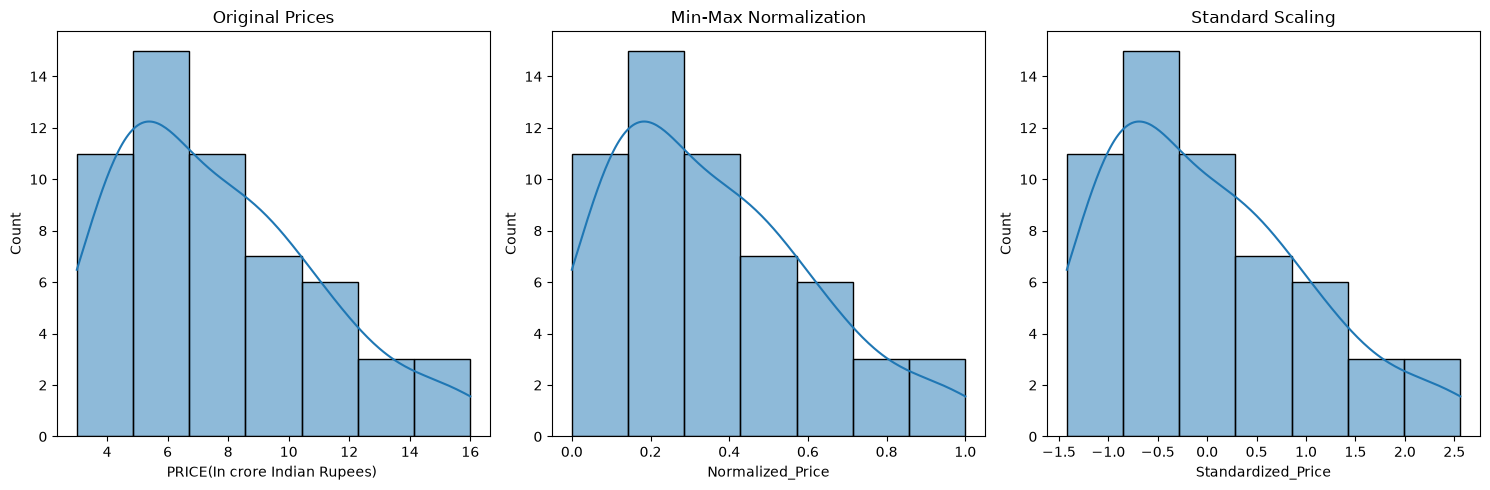

In [10]:
# Compare the three price distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(auction_features[price_col].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Original Prices")

sns.histplot(auction_features["Normalized_Price"].dropna(), kde=True, ax=axes[1])
axes[1].set_title("Min-Max Normalization")

sns.histplot(auction_features["Standardized_Price"].dropna(), kde=True, ax=axes[2])
axes[2].set_title("Standard Scaling")

plt.tight_layout()
plt.show()

In [11]:
# Select categorical columns for encoding
categorical_features = auction[["TEAM", "TYPE"]].copy()

# Apply One-Hot Encoding
encoded_features = pd.get_dummies(
    categorical_features,
    columns=["TEAM", "TYPE"],
    dtype=int
)

print("Encoded Categorical Features:")
print(encoded_features.head())

print("\nEncoded Dataset Shape:", encoded_features.shape)

Encoded Categorical Features:
   TEAM_ Chennai Super Kings  TEAM_ Delhi Capitals  TEAM_ Delhi Daredevils  \
0                          0                     0                       0   
1                          0                     0                       0   
2                          0                     0                       0   
3                          0                     0                       0   
4                          0                     0                       0   

   TEAM_ Kings XI Punjab  TEAM_ Kolkata Knight Riders  TEAM_ Mumbai Indians  \
0                      0                            1                     0   
1                      1                            0                     0   
2                      0                            0                     0   
3                      1                            0                     0   
4                      0                            0                     1   

   TEAM_ Rajasthan Royals 

In [12]:
# Apply Label Encoding to player types
label_encoder = LabelEncoder()

type_encoding = auction[["TYPE"]].copy()
type_encoding["Encoded_TYPE"] = label_encoder.fit_transform(
    type_encoding["TYPE"].astype(str)
)

print(type_encoding.head(10))

print("\nCategory Mapping:")
for category, code in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{category} = {code}")

          TYPE  Encoded_TYPE
0  All-Rounder             0
1  All-Rounder             0
2  All-Rounder             0
3       Bowler             2
4       Bowler             2
5      Batsman             1
6       Bowler             2
7  All-Rounder             0
8       Bowler             2
9  All-Rounder             0

Category Mapping:
All-Rounder = 0
Batsman = 1
Bowler = 2
Wicket Keeper = 3


In [13]:
# Calculate skewness of auction prices
price_skewness = auction[price_col].dropna().skew()

print("Auction Price Skewness:", round(price_skewness, 3))

if price_skewness > 0:
    print("The distribution is positively (right) skewed.")
elif price_skewness < 0:
    print("The distribution is negatively (left) skewed.")
else:
    print("The distribution is approximately symmetric.")

Auction Price Skewness: 0.744
The distribution is positively (right) skewed.


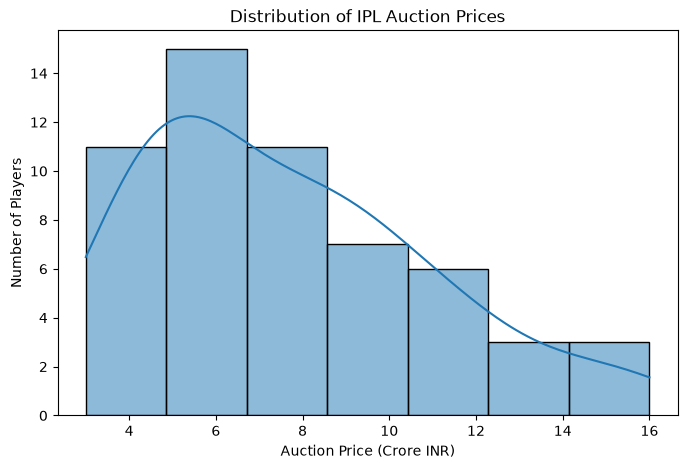

In [14]:
# Visualize the distribution of auction prices
plt.figure(figsize=(8, 5))

sns.histplot(auction[price_col].dropna(), kde=True)

plt.title("Distribution of IPL Auction Prices")
plt.xlabel("Auction Price (Crore INR)")
plt.ylabel("Number of Players")

plt.show()

In [15]:
# Apply log transformation to auction prices
auction_features["Log_Transformed_Price"] = np.log1p(
    auction_features[price_col]
)

print(auction_features[[price_col, "Log_Transformed_Price"]].head(10))

print("\nOriginal Skewness:",
      round(auction_features[price_col].skew(), 3))

print("Log-Transformed Skewness:",
      round(auction_features["Log_Transformed_Price"].skew(), 3))

   PRICE(In crore Indian Rupees)   Log_Transformed_Price
0                           15.50               2.803360
1                           10.75               2.463853
2                           10.00               2.397895
3                            8.50               2.251292
4                            8.00               2.197225
5                            7.75               2.169054
6                            6.75               2.047693
7                            5.50               1.871802
8                            8.40               2.240710
9                            8.40               2.240710

Original Skewness: 0.744
Log-Transformed Skewness: 0.109


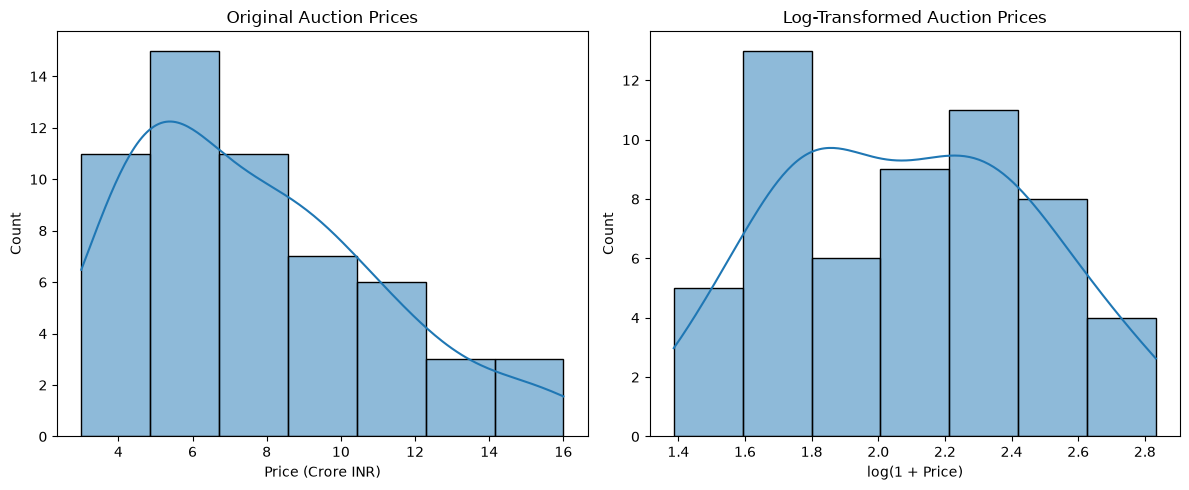

In [16]:
# Compare original and log-transformed price distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(auction_features[price_col].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Original Auction Prices")
axes[0].set_xlabel("Price (Crore INR)")

sns.histplot(
    auction_features["Log_Transformed_Price"].dropna(),
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Auction Prices")
axes[1].set_xlabel("log(1 + Price)")

plt.tight_layout()
plt.show()

In [17]:
# Identify numerical batting columns
batting_numeric = batsmen.select_dtypes(include=np.number)

print("Numerical Batting Columns:")
print(batting_numeric.columns.tolist())

print("\nSkewness of Batting Features:")
print(batting_numeric.skew().sort_values(ascending=False).round(3))

Numerical Batting Columns:
['POS', 'Mat', 'Inns', 'NO', 'Runs', 'Avg', 'BF', 'SR', 100, 50, '4s', '6s']

Skewness of Batting Features:
100     2.790
6s      1.980
50      1.620
NO      1.499
Runs    1.297
SR      1.269
4s      1.260
BF      1.229
Inns    0.943
Mat     0.726
Avg     0.329
POS     0.000
dtype: float64


In [18]:
# Identify numerical bowling columns
bowling_numeric = bowlers.select_dtypes(include=np.number)

print("Numerical Bowling Columns:")
print(bowling_numeric.columns.tolist())

print("\nSkewness of Bowling Features:")
print(bowling_numeric.skew().sort_values(ascending=False).round(3))

Numerical Bowling Columns:
['POS', 'Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'BBI', 'Avg', 'Econ', 'SR', '4w', '5w']

Skewness of Bowling Features:
5w      2.833
4w      2.071
SR      1.286
Wkts    1.211
Mat     1.078
Ov      1.050
Inns    0.944
Avg     0.944
Runs    0.919
Econ    0.061
POS     0.000
BBI     0.000
dtype: float64


## Feature Engineering Summary

### 1. Normalization
Min-Max Scaling was applied to auction prices to transform values into the range 0 to 1.

### 2. Standardization
Standard Scaling was applied to center auction prices around a mean of 0 with a standard deviation of approximately 1.

### 3. Categorical Encoding
One-Hot Encoding was used for categorical features such as TEAM and TYPE. Label Encoding was demonstrated for player types.

### 4. Skewness Analysis
Skewness was calculated for auction prices, batting statistics, and bowling statistics to identify asymmetric distributions.

### 5. Log Transformation
A log1p transformation was applied to auction prices and its effect was evaluated using skewness values and distribution plots.

### Conclusion
Feature engineering helps prepare numerical and categorical data for further statistical analysis and dimensionality reduction. Transformations should be selected according to the characteristics of each feature.

In [19]:
# Validate transformed auction features
transformed_cols = [
    "Normalized_Price",
    "Standardized_Price",
    "Log_Transformed_Price"
]

print("Missing Values:")
print(auction_features[transformed_cols].isnull().sum())

print("\nInfinite Values:")
print(
    np.isinf(auction_features[transformed_cols])
    .sum()
)

print("\nSummary Statistics:")
print(auction_features[transformed_cols].describe())

Missing Values:
Normalized_Price         0
Standardized_Price       0
Log_Transformed_Price    0
dtype: int64

Infinite Values:
Normalized_Price         0
Standardized_Price       0
Log_Transformed_Price    0
dtype: int64

Summary Statistics:
       Normalized_Price  Standardized_Price  Log_Transformed_Price
count         56.000000        5.600000e+01              56.000000
mean           0.356662        6.344132e-17               2.086751
std            0.253473        1.009050e+00               0.375086
min            0.000000       -1.419833e+00               1.386294
25%            0.153846       -8.073880e-01               1.791759
50%            0.307692       -1.949433e-01               2.079442
75%            0.501923        5.782681e-01               2.353745
max            1.000000        2.561058e+00               2.833213
